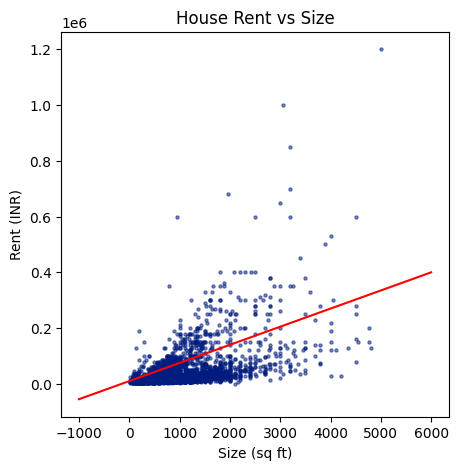

In [1]:
#%matplotlib ipympl
import kagglehub
import numpy as np
from numpy.typing import NDArray
import matplotlib.pyplot as plt
from kagglehub import KaggleDatasetAdapter

file = "House_Rent_Dataset.csv"

df = kagglehub.dataset_load(KaggleDatasetAdapter.PANDAS, "iamsouravbanerjee/house-rent-prediction-dataset", file)
cropped_df = df[["Rent", "Size"]].query('Rent <= 2000000 and Size <= 5000')

m = 65
b = 0.01 * np.pow(10, 6)
x_line = np.linspace(-1000, 6000)
y_line = m * x_line + b

# Plotting the data
#print(plt.style.available)
plt.style.use('seaborn-v0_8-dark-palette')
plt.figure(figsize=(5, 5))
plt.scatter(cropped_df["Size"], cropped_df["Rent"], alpha=0.5, s=5)
plt.title("House Rent vs Size")
plt.xlabel("Size (sq ft)")
plt.ylabel("Rent (INR)")
plt.plot(x_line, y_line, color='red', label='y = mx + b')
plt.show()

In [2]:
def get_cost_function(rent: NDArray, size: NDArray, w_vals: NDArray[np.float64], b_vals: NDArray[np.float64]) -> tuple[NDArray[np.float64], NDArray[np.float64], NDArray[np.float64]]:
    
    W, B = np.meshgrid(w_vals, b_vals)    
    J_vals = np.zeros_like(W)

    count = rent.size
    for i in range(W.shape[0]):
        for j in range(W.shape[1]):
            w = W[i, j]
            b = B[i, j]
            pred = w * size + b
            J_vals[i, j] = (1/(2*count)) * np.sum((pred - rent) ** 2)
    
    return W, B, J_vals

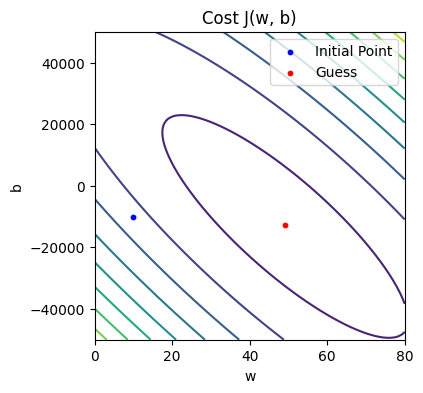

In [3]:
rent: NDArray = cropped_df["Rent"].values
size: NDArray = cropped_df["Size"].values

w_vals = np.linspace(0, 80, 100)
b_vals = np.linspace(-50000, 50000, 100)
        
fig, ax = plt.subplots(figsize=(4, 4))
plt.contour(*get_cost_function(rent, size, w_vals, b_vals), levels=10, cmap='viridis')
plt.scatter([10], [-10000], color='blue', s=10, label='Initial Point')
plt.scatter([49], [-12600], color='red', s=10, label='Guess')
plt.xlabel('w')
plt.ylabel('b')
plt.title('Cost J(w, b)')
plt.legend()
plt.show()

In [4]:
def get_cost(rent: NDArray, size: NDArray, w: float, b: float) -> float:
    count = rent.size
    pred = w * size + b
    return (1/(2*count)) * np.sum((pred - rent) ** 2)

def dCostdw(rent: NDArray, size: NDArray, w: float, b: float) -> float:
    count = rent.size
    pred = w * size + b
    return (1/count) * np.sum((pred - rent) * size)

def dCostdb(rent: NDArray, size: NDArray, w: float, b: float) -> float:
    count = rent.size
    pred = w * size + b
    return (1/count) * np.sum(pred - rent)

In [33]:
w, b = (40, 0)
iterations = 100000
learning_rate = 0.000001

for i in range(iterations):
    dw = dCostdw(rent, size, w, b)
    db = dCostdb(rent, size, w, b)
    
    w -= learning_rate * dw
    b -= learning_rate * db
    print(f"w = {w}, b = {b}, dw= {dw}, db = {db}")


w = 39.19424778422274, b = -0.004402345496730648, dw= 805752.2157772622, db = 4402.345496730648
w = 39.435960107723126, b = -0.008029269306205837, dw= -241712.3235003864, db = 3626.9238094751895
w = 39.36345517411116, b = -0.011888801835267674, dw= 72504.93361196978, db = 3859.5325290618366
w = 39.385208786696715, b = -0.015678555234356385, dw= -21753.61258555736, db = 3789.753399088712
w = 39.37868682456258, b = -0.019489239477041485, dw= 6521.962134140198, db = 3810.684242685099
w = 39.38064693814308, b = -0.02329364348550752, dw= -1960.1135805021784, db = 3804.4040084660346
w = 39.38006260800561, b = -0.027099930008863425, dw= 584.330137470457, db = 3806.286523355907
w = 39.380241557287015, b = -0.030905650394635647, dw= -178.94928140726756, db = 3805.7203857722216
w = 39.38019153884921, b = -0.03471153918689268, dw= 50.018437802150416, db = 3805.888792257036
w = 39.38021020589421, b = -0.038517376037915496, dw= -18.667044994625403, db = 3805.8368510228156
w = 39.38020826874278, b =

KeyboardInterrupt: 